## **Enrollment No.:240840116002**

# **PRACTICAL-10**

**AIM**:Mini Project: Analyze a real-world dataset, build an interactive dashboard, and present actionable
insights with ethical considerations.

**Step 1: Project Title and Problem Statement**

**Title:** IPL Ball-by-Ball Data Cleaning, Analysis and Power BI Dashboard.


**Problem statement:** The objective is to clean and analyse IPL delivery records to understand batting performance, bowling performance, team scoring patterns, extras, boundaries, wickets and scoring patterns across innings phases. The cleaned dataset will be used to build an interactive Power BI dashboard.

**Work flow:** Raw CSV file, then data cleaning in Python (Pandas), then the cleaned CSV file, then Power BI dashboard (4
KPIs and charts), then insights and ethical considerations.

**Dataset:** deliveries.csv with 260,920
Delivery records  and 17 Columns:
match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder.

**Step 2: Import Libraries**

**What we do:** Load the Python libraries that are needed in the whole project before any data work starts.
What we use: Pandas (reading the CSV file, cleaning, grouping and tables), NumPy (numeric calculations), Matplotlib
and Seaborn (charts that show the data before and after cleaning and the insights). import ... as ... gives a short name
(pd, np, plt, sns) to a library

In [ ]:
# Pandas -> reading the CSV file, cleaning and tables (DataFrames)
# NumPy -> numeric calculations
# Matplotlib -> basic charts, Seaborn -> attractive statistical charts
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Seaborn theme gives all charts a clean grid style
sns.set_theme(style="whitegrid")

**Step 3: Load the Dataset from the CSV File**

**What we do:** Read the raw sales file into a table (DataFrame) and keep an untouched copy of it, so that the data before
and after cleaning can be compared at the end.


**What we use:** pd.read_csv() to read the file, .shape to count rows and columns, .copy() to make a backup, .head() to
show the first 5 rows.

In [ ]:
# read_csv() loads the CSV file into a DataFrame
# The file must be in the same folder as the notebook (in Google Colab upload it from the Files panel)
df = pd.read_csv("deliveries.csv")
# Keep the number of rows and columns of the raw data, they are compared with the clean data at the end
raw_shape = df.shape
# Keep an untouched copy of the raw data for the before and after comparison
raw_df = df.copy()
# Display the first 5 rows
df.head()

,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


**Step 4: Data Inspection (find the problems in the data)**



**What we do:** Check the raw data carefully and list every problem that has to be cleaned: size, data types, summary
numbers, missing values, duplicates and spelling differences.

**What we use:** .shape, .info() (data types and non-null counts), .describe() (count, mean, min, quartiles, max),
.isnull().sum() (missing values), .duplicated().sum() (duplicate rows) and .unique() (different values of a column)

Task 1: Dimension of the dataset

In [ ]:
# shape -> (number of rows, number of columns)
df.shape

(260920, 17)

Task 2: Data types and non-null counts

In [ ]:
# info() shows the data type of every column and how many values are not missing
# Unit Price is shown as object (text) because some prices are written like 'Rs. 1,200'
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260920 entries, 0 to 260919
Data columns (total 17 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   match_id          260920 non-null  int64 
 1   inning            260920 non-null  int64 
 2   batting_team      260920 non-null  object
 3   bowling_team      260920 non-null  object
 4   over              260920 non-null  int64 
 5   ball              260920 non-null  int64 
 6   batter            260920 non-null  object
 7   bowler            260920 non-null  object
 8   non_striker       260920 non-null  object
 9   batsman_runs      260920 non-null  int64 
 10  extra_runs        260920 non-null  int64 
 11  total_runs        260920 non-null  int64 
 12  extras_type       14125 non-null   object
 13  is_wicket         260920 non-null  int64 
 14  player_dismissed  12950 non-null   object
 15  dismissal_kind    12950 non-null   object
 16  fielder           9354 non-null    obj

Task 3: Statistical summary

In [ ]:
# describe() summarises the numerical columns
# A negative or very large Quantity is a wrong value
df.describe()

,match_id,inning,over,ball,batsman_runs,extra_runs,total_runs,is_wicket
count,2.609200e+05,260920.000000,260920.000000,260920.000000,260920.000000,260920.000000,260920.000000,260920.000000
mean,9.070665e+05,1.483531,9.197677,3.624486,1.265001,0.067806,1.332807,0.049632
std,3.679913e+05,0.502643,5.683484,1.814920,1.639298,0.343265,1.626416,0.217184
min,3.359820e+05,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,5.483340e+05,1.000000,4.000000,2.000000,0.000000,0.000000,0.000000,0.000000
50%,9.809670e+05,1.000000,9.000000,4.000000,1.000000,0.000000,1.000000,0.000000
75%,1.254066e+06,2.000000,14.000000,5.000000,1.000000,0.000000,1.000000,0.000000
max,1.426312e+06,6.000000,19.000000,11.000000,6.000000,7.000000,7.000000,1.000000


Task 4: Missing values and duplicate rows

In [ ]:
# isnull().sum() counts the missing values of every column
print("Missing values per column:")
print(df.isnull().sum())
# duplicated().sum() counts the rows that are an exact copy of an earlier row
print()
print("Duplicate rows :", df.duplicated().sum())

Missing values per column:
match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
ball                     0
batter                   0
bowler                   0
non_striker              0
batsman_runs             0
extra_runs               0
total_runs               0
extras_type         246795
is_wicket                0
player_dismissed    247970
dismissal_kind      247970
fielder             251566
dtype: int64

Duplicate rows : 0


In [ ]:
# unique() shows every different value of a column
# Royal Challengers Bangalore,Royal Challengers Bengaluru and Rising Pune Supergiants ,Rising Pune Supergiant are same teams but treated as diffrent values
print(df["batting_team"].unique().tolist())
print()
print(df["bowling_team"].unique().tolist())

['Kolkata Knight Riders', 'Royal Challengers Bangalore', 'Chennai Super Kings', 'Kings XI Punjab', 'Rajasthan Royals', 'Delhi Daredevils', 'Mumbai Indians', 'Deccan Chargers', 'Kochi Tuskers Kerala', 'Pune Warriors', 'Sunrisers Hyderabad', 'Rising Pune Supergiants', 'Gujarat Lions', 'Rising Pune Supergiant', 'Delhi Capitals', 'Punjab Kings', 'Lucknow Super Giants', 'Gujarat Titans', 'Royal Challengers Bengaluru']

['Royal Challengers Bangalore', 'Kolkata Knight Riders', 'Kings XI Punjab', 'Chennai Super Kings', 'Delhi Daredevils', 'Rajasthan Royals', 'Mumbai Indians', 'Deccan Chargers', 'Kochi Tuskers Kerala', 'Pune Warriors', 'Sunrisers Hyderabad', 'Rising Pune Supergiants', 'Gujarat Lions', 'Rising Pune Supergiant', 'Delhi Capitals', 'Punjab Kings', 'Gujarat Titans', 'Lucknow Super Giants', 'Royal Challengers Bengaluru']


**Step 5: Clean the Text Columns**

**What we use:** A for loop over the text columns, .str.strip() (remove spaces at the start and end) and .str.title() (first letter
of every word capital). Missing values are not changed by these functions

**What we do:** Make the spelling of the text columns the same, so that every region, category, sub-category, segment and
customer has only one form

In [ ]:
# strip() removes the extra spaces at the start and end
# title() makes the first letter of every word capital, so 'NORTH' and 'north' both become 'North'
# Missing values (NaN) are not changed by these functions
text_cols = [

    "batting_team", "bowling_team", "batter", "bowler",

    "non_striker", "extras_type", "player_dismissed",

    "dismissal_kind", "fielder"

]

for col in text_cols:

    df[col] = df[col].astype("string").str.strip()

    df[col] = df[col].replace("", pd.NA)

# Inspect team-name variants before applying any mapping

print(sorted(df["batting_team"].dropna().unique()))


['Chennai Super Kings', 'Deccan Chargers', 'Delhi Capitals', 'Delhi Daredevils', 'Gujarat Lions', 'Gujarat Titans', 'Kings XI Punjab', 'Kochi Tuskers Kerala', 'Kolkata Knight Riders', 'Lucknow Super Giants', 'Mumbai Indians', 'Pune Warriors', 'Punjab Kings', 'Rajasthan Royals', 'Rising Pune Supergiant', 'Rising Pune Supergiants', 'Royal Challengers Bangalore', 'Royal Challengers Bengaluru', 'Sunrisers Hyderabad']


**STEP 6: Correct and validate data types**

In [ ]:
numeric_cols = [
    "match_id", "inning", "over", "ball", "batsman_runs",
    "extra_runs", "total_runs", "is_wicket"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")
# These columns should be whole-number values
for col in numeric_cols:
    invalid_fraction = df[col].dropna().mod(1).ne(0).sum()
    print(col, "non-integer values:", invalid_fraction)
print(df[numeric_cols].dtypes)

match_id non-integer values: 0
inning non-integer values: 0
over non-integer values: 0
ball non-integer values: 0
batsman_runs non-integer values: 0
extra_runs non-integer values: 0
total_runs non-integer values: 0
is_wicket non-integer values: 0
match_id        int64
inning          int64
over            int64
ball            int64
batsman_runs    int64
extra_runs      int64
total_runs      int64
is_wicket       int64
dtype: object


In [ ]:
checks = {
    "inning_outside_1_to_6": ~df["inning"].between(1, 6),
    "negative_over": df["over"] < 0,
    "over_above_19": df["over"] > 19,
    "ball_below_1": df["ball"] < 1,
    "negative_batsman_runs": df["batsman_runs"] < 0,
    "negative_extra_runs": df["extra_runs"] < 0,
    "negative_total_runs": df["total_runs"] < 0,
    "invalid_is_wicket": ~df["is_wicket"].isin([0, 1]),
}
for label, mask in checks.items():
    print(label, int(mask.fillna(False).sum()))
print("Run-total mismatches:",
      int((df["total_runs"] != df["batsman_runs"] + df["extra_runs"]).sum()))

inning_outside_1_to_6 0
negative_over 0
over_above_19 0
ball_below_1 0
negative_batsman_runs 0
negative_extra_runs 0
negative_total_runs 0
invalid_is_wicket 0
Run-total mismatches: 0


STEP 7: Handle missing values

In [ ]:
df["extras_type_label"] = df["extras_type"].fillna("No Extra")
df["dismissal_kind_label"] = df["dismissal_kind"].fillna("No Dismissal")
df["player_dismissed_label"] = df["player_dismissed"].fillna("No Dismissal")

STEP 8: Create new features (feature engineering)

In [ ]:
#Create delivery-level indicators that make cricket analysis easier. In this dataset over numbering starts at 0; powerplay overs are 0–5 and the final four overs are 16–19.
df["is_four"] = (df["batsman_runs"] == 4).astype("int8")
df["is_six"] = (df["batsman_runs"] == 6).astype("int8")
df["is_boundary"] = df["batsman_runs"].isin([4, 6]).astype("int8")
df["is_extra"] = (df["extra_runs"] > 0).astype("int8")
df["is_dot_ball"] = (df["total_runs"] == 0).astype("int8")
df["is_powerplay"] = df["over"].between(0, 5).astype("int8")
df["is_death_over"] = df["over"].between(16, 19).astype("int8")
# Credited wickets: exclude dismissal kinds not credited to the bowler
not_bowler_credited = [
    "run out", "retired hurt", "obstructing the field", "retired out"
]
df["bowler_credited_wicket"] = (
    (df["is_wicket"] == 1) &
    (~df["dismissal_kind"].str.lower().isin(not_bowler_credited))
).astype("int8")
df[["is_four", "is_six", "is_boundary", "is_extra",
    "is_dot_ball", "is_powerplay", "is_death_over"]].head()

,is_four,is_six,is_boundary,is_extra,is_dot_ball,is_powerplay,is_death_over
0,0,0,0,1,0,1,0
1,0,0,0,0,1,1,0
2,0,0,0,1,0,1,0
3,0,0,0,0,1,1,0
4,0,0,0,0,1,1,0


STEP 9: Validate the cleaned dataset

In [ ]:

print("Shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
print("Null counts:")
print(df.isna().sum())
assert (df["total_runs"] == df["batsman_runs"] + df["extra_runs"]).all()
assert df["is_wicket"].isin([0, 1]).all()
assert df["is_boundary"].isin([0, 1]).all()
assert df["is_powerplay"].isin([0, 1]).all()
print("Core validation checks passed.")

Shape: (260920, 28)
Duplicates: 0
Null counts:
match_id                       0
inning                         0
batting_team                   0
bowling_team                   0
over                           0
ball                           0
batter                         0
bowler                         0
non_striker                    0
batsman_runs                   0
extra_runs                     0
total_runs                     0
extras_type               246795
is_wicket                      0
player_dismissed          247970
dismissal_kind            247970
fielder                   251566
extras_type_label              0
dismissal_kind_label           0
player_dismissed_label         0
is_four                        0
is_six                         0
is_boundary                    0
is_extra                       0
is_dot_ball                    0
is_powerplay                   0
is_death_over                  0
bowler_credited_wicket         0
dtype: int64
Core validation 

STEP 10: Save the cleaned dataset

In [ ]:
df.to_csv("ipl_deliveries_cleaned.csv", index=False)
print("Saved:")

Saved:


STEP 11: Compare before and after cleaning

In [ ]:

comparison = pd.DataFrame({
    "Metric": ["Rows", "Columns", "Duplicate rows", "Missing extras_type",
               "Missing player_dismissed", "Missing dismissal_kind", "Missing fielder"],
    "Before": [
        260920, 17, 0, 246795, 247970, 247970, 251566
    ],
    "After": [
        len(df), len(df.columns), df.duplicated().sum(),
        df["extras_type"].isna().sum(),
        df["player_dismissed"].isna().sum(),
        df["dismissal_kind"].isna().sum(),
        df["fielder"].isna().sum()
    ]
})
print(comparison)

                     Metric  Before   After
0                      Rows  260920  260920
1                   Columns      17      28
2            Duplicate rows       0       0
3       Missing extras_type  246795  246795
4  Missing player_dismissed  247970  247970
5    Missing dismissal_kind  247970  247970
6           Missing fielder  251566  251566


STEP 12: Calculate key performance indicators (KPIs)

In [ ]:
#These figures are from the supplied CSV, before any team-alias consolidation.
kpis = {
    "Total Matches": df["match_id"].nunique(),
    "Total Runs": df["total_runs"].sum(),
    "Dismissal Events": df["is_wicket"].sum(),
    "Team Name Entries": df["batting_team"].nunique(),
    "Fours": df["is_four"].sum(),
    "Sixes": df["is_six"].sum(),
    "Boundaries": df["is_boundary"].sum(),
    "Extras": df["extra_runs"].sum(),
    "Dot-ball records": df["is_dot_ball"].sum()
}
print(pd.Series(kpis))

Total Matches          1095
Total Runs           347756
Dismissal Events      12950
Team Name Entries        19
Fours                 29850
Sixes                 13051
Boundaries            42901
Extras                17692
Dot-ball records      90438
dtype: int64


**STEP 13: Create DAX measures**
### DAX Measures for Power BI
These measures are designed to be created inside Power BI using your cleaned dataset:

```dax
Total_Runs = SUM(ipl_deliveries_cleaned[total_runs])
Batter_Runs = SUM(ipl_deliveries_cleaned[batsman_runs])
Total_Matches = DISTINCTCOUNT(ipl_deliveries_cleaned[match_id])
Dismissal_Events = SUM(ipl_deliveries_cleaned[is_wicket])
Fours = SUM(ipl_deliveries_cleaned[is_four])
Sixes = SUM(ipl_deliveries_cleaned[is_six])
Total_Boundaries = SUM(ipl_deliveries_cleaned[is_boundary])
Extras = SUM(ipl_deliveries_cleaned[extra_runs])
Dot_Ball_Records = SUM(ipl_deliveries_cleaned[is_dot_ball])
Bowler_Credited_Wickets = SUM(ipl_deliveries_cleaned[bowler_credited_wicket])
Powerplay_Runs = CALCULATE([Total_Runs], ipl_deliveries_cleaned[is_powerplay] = 1)
Death_Overs_Runs = CALCULATE([Total_Runs], ipl_deliveries_cleaned[is_death_over] = 1)
```

**STEP 14: Design the IPL dashboard**

Create one report page titled IPL Ball-by-Ball Performance Dashboard. Suggested layout:

Top row: cards for Total Matches, Total Runs, Dismissal Events and Total Boundaries.

Middle left: horizontal bar chart for top 10 batters by Batter Runs.

Middle right: horizontal bar chart for top 10 bowlers by Bowler Credited Wickets.

Bottom left: column chart for Total Runs by Batting Team.

Bottom right: comparison of Powerplay Runs and Death Overs Runs.

Add slicers for batting_team, bowling_team and inning.

Keep team labels readable and use consistent formatting. Since the CSV has no date or season field, do not add a season slicer.

**STEP 15: Check and save the Power BI report**

Check that cards show values and no measure errors.

Check that the Top 10 charts are sorted descending.

Check that slicers filter all relevant visuals.

Verify that team names with historical aliases remain separate unless you documented a mapping.

Save the report as IPL_Analysis_Dashboard.pbix.

**STEP 16: Capture dashboard screenshot**

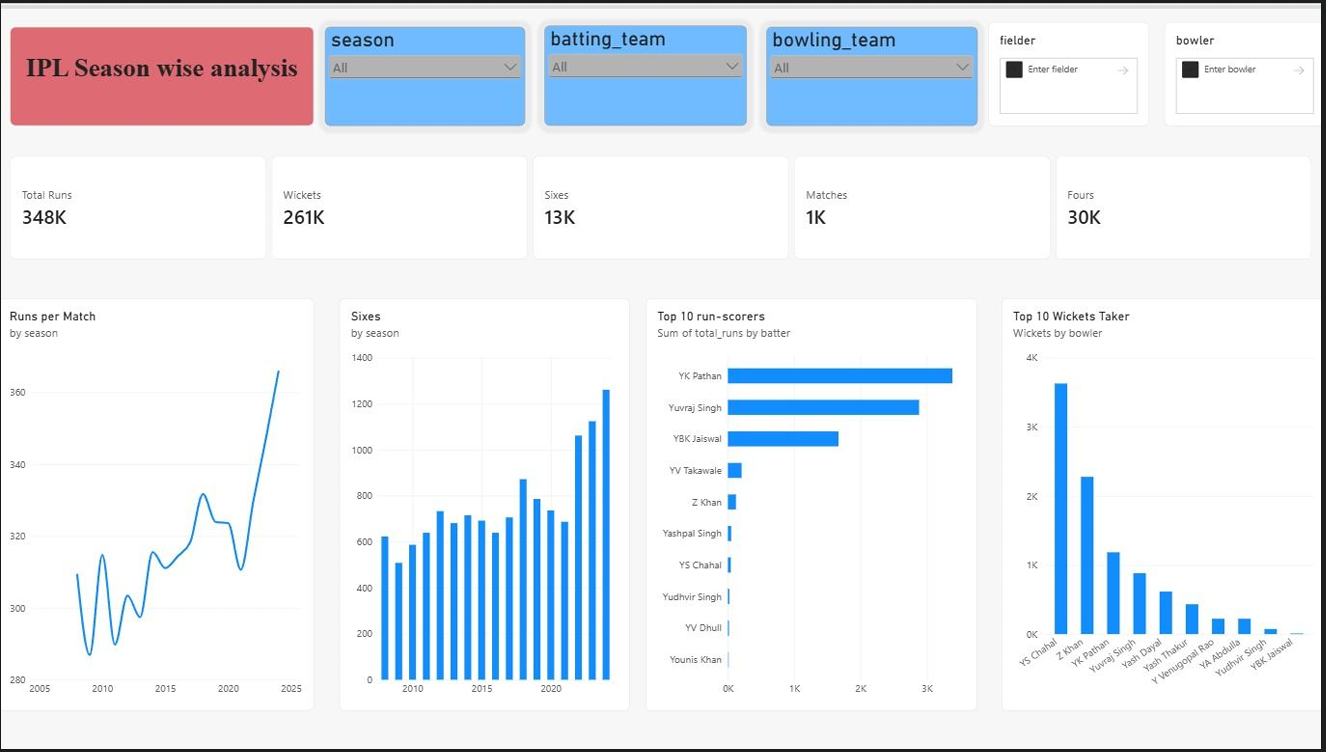

**STEP 17: Write insights from the analysis**

The following results are calculated from the uploaded CSV. They can be included as observations, with the scope limitations stated.

### **Top Run Scorers (by Batter Runs)**

| Batter | Runs |
| :--- | :--- |
| **V Kohli** | 8,014 |
| **S Dhawan** | 6,769 |
| **RG Sharma** | 6,630 |
| **DA Warner** | 6,567 |
| **SK Raina** | 5,536 |

<br>

### **Top Bowlers (by Credited Wickets)**

| Bowler | Credited Wickets |
| :--- | :--- |
| **YS Chahal** | 205 |
| **PP Chawla** | 192 |
| **DJ Bravo** | 183 |
| **B Kumar** | 181 |
| **SP Narine** | 180 |

<br>

### **Top Recorded Batting Teams (by Total Runs)**

| Batting Team Label | Runs |
| :--- | :--- |
| **Mumbai Indians** | 42,176 |
| **Kolkata Knight Riders** | 39,331 |
| **Chennai Super Kings** | 38,629 |
| **Royal Challengers Bangalore** | 37,692 |
| **Rajasthan Royals** | 34,747 |


* Across the file, 347,756 total runs were recorded, of which 330,064 were batter runs and 17,692 were extras.

* The dataset contains 42,901 batter-scored boundaries: 29,850 fours and 13,051 sixes.

* There are 12,950 dismissal events. Credited wickets for bowlers are lower because some dismissal types are not credited to the bowler.

* Powerplay overs (0–5) account for 103,217 total runs in the supplied delivery records; death overs (16–19) account for 75,412.

* Team totals are grouped by the exact team labels in the file. Historical names are separate categories, so these figures should not be interpreted as franchise-lifetime totals.

* These are descriptive results, not proof that one player or team is better in every context. The dataset spans different match situations and does not provide season, venue, opposition strength or match-result context.





**STEP 18: Ethical considerations and conclusion**

Ethical considerations:

Use the dataset only for educational and analytical purposes.

Do not invent missing match details or claim that the data contains seasons, venues, toss outcomes or match winners.

Preserve source values and document any team-name mapping or data transformation.

Explain how missing values were treated; do not misrepresent meaningful missing values as errors.

Use accurate labels for dismissal events and bowler-credited wickets.

Avoid unsupported conclusions from raw totals; player opportunities, number of matches and playing roles can differ.



**Conclusion:** This practical used Python and Pandas to inspect, clean, validate and transform IPL ball-by-ball delivery data. Derived indicators were created for boundaries, extras, dot balls, powerplay and death overs. The resulting dataset supports batting, bowling and team-level descriptive analysis in Power BI. The analysis is limited to the fields available in deliveries.csv; additional match-level data would be required for season-wise, venue-wise, toss-wise and match-winner analysis.